## 1.1 — Préparer l'environnement et les paramètres

On importe `requests` pour communiquer avec l'API et `pandas` pour manipuler les réponses. On prépare également un répertoire `data/` afin d'y stocker les CSV.

**Pré-requis :** disposer de `requests`, `pandas` et `matplotlib`. Dans Jupyter, si une librairie manque, exécuter dans une cellule distincte : `%pip install requests pandas matplotlib`.

In [2]:
from pathlib import Path
from urllib.parse import urljoin
import time

import requests
import pandas as pd
import matplotlib.pyplot as plt

# Dossier des exports : créé dans le dossier de travail du notebook.
DOSSIER_DATA = Path("data")
DOSSIER_DATA.mkdir(parents=True, exist_ok=True)

# La Corse est la région administrative 94 (les deux départements 2A et 2B).
CODE_REGION = "94"
FILTRE_REGION = f'code_region_ban:"{CODE_REGION}"'

# Les deux jeux DPE officiels de l'ADEME (depuis juillet 2021).
BASE_URL = "https://data.ademe.fr/data-fair/api/v1/datasets"
APIS = {
    "existants": "dpe03existant",
    "neufs": "dpe02neuf",
}

# On limite d'abord l'extraction à 2 pages par API pour la démonstration.
# Passer à None plus tard UNIQUEMENT après validation des tests.
TAILLE_PAGE = 200
MAX_PAGES = 2

print("Région étudiée : Corse (94)")
print("Filtre ADEME :", FILTRE_REGION)
print("Dossier de sortie :", DOSSIER_DATA.resolve())

Matplotlib is building the font cache; this may take a moment.


Région étudiée : Corse (94)
Filtre ADEME : code_region_ban:"94"
Dossier de sortie : C:\Users\user\data


## 1.2 — Tester les deux API (3 logements chacune)

Une réponse avec le **code HTTP 200** signifie que la requête a été acceptée. On contrôle ensuite :

1. Le nombre total annoncé par l'API (`total`).
2. Le nombre de lignes reçues (`results`).
3. Le champ de pagination (`next`).
4. Le code région et les codes départements des logements renvoyés.

Ici, on ne filtre **ni les classes DPE ni les dates** : les datasets officiels concernent déjà les DPE depuis juillet 2021 et nous voulons conserver les classes A à G.

In [3]:
# Une session réutilise les connexions HTTP pour plusieurs requêtes.
session = requests.Session()

for nom, dataset in APIS.items():
    url = f"{BASE_URL}/{dataset}/lines"
    params_test = {
        "qs": FILTRE_REGION,  # Filtre géographique : Corse
        "size": 3,           # Petit échantillon de vérification
    }

    print(f"\n===== TEST API : {nom.upper()} =====")
    reponse = session.get(url, params=params_test, timeout=45)
    print("Statut HTTP :", reponse.status_code)
    reponse.raise_for_status()  # Arrêt explicite si 4xx / 5xx

    contenu = reponse.json()
    lignes = contenu.get("results", [])

    print("Total annoncé par l'API :", contenu.get("total"))
    print("Lignes reçues :", len(lignes))
    print("La pagination 'next' est présente :", bool(contenu.get("next")))

    if lignes:
        echantillon = pd.DataFrame(lignes)
        # Ces champs sont utiles pour valider le périmètre.
        colonnes_controle = [
            c for c in [
                "numero_dpe", "code_region_ban", "code_departement_ban",
                "etiquette_dpe", "date_reception_dpe"
            ] if c in echantillon.columns
        ]
        display(echantillon[colonnes_controle])
    else:
        print("Aucune ligne retournée : vérifier le filtre et la disponibilité de l'API.")


===== TEST API : EXISTANTS =====
Statut HTTP : 200
Total annoncé par l'API : 54399
Lignes reçues : 3
La pagination 'next' est présente : True


,numero_dpe,code_region_ban,code_departement_ban,etiquette_dpe,date_reception_dpe
0,2620E0070380X,94,2A,C,2026-01-12
1,2620E0048320L,94,2B,E,2026-01-08
2,2120E0428126E,94,2A,D,2021-10-01



===== TEST API : NEUFS =====
Statut HTTP : 200
Total annoncé par l'API : 5303
Lignes reçues : 3
La pagination 'next' est présente : True


,numero_dpe,code_region_ban,code_departement_ban,etiquette_dpe,date_reception_dpe
0,2620N0025074S,94,2B,A,2026-01-06
1,2620N0011394O,94,2A,A,2026-01-05
2,2420N3326336G,94,2A,A,2024-09-24


## 1.3 — Automatiser l'extraction avec `next`

Le cours insiste sur la pagination : chaque requête ne récupère qu'une **page**. Le champ `next` de la réponse indique où trouver la page suivante. Il faut donc suivre ce lien jusqu'à sa disparition (ou s'arrêter au nombre de pages choisi pour notre démonstration).

**Pourquoi ne pas boucler sur `page=1, 2, 3...` ?** La pagination profonde peut rencontrer des limites. `next` est prévu pour reprendre correctement la lecture d'une page à l'autre.

Le script ci-dessous conserve les **colonnes brutes** : la sélection et le nettoyage auront lieu dans une étape distincte.

In [4]:
def extraire_dpe(nom, dataset, taille_page=200, max_pages=2):
    """
    Récupère les DPE d'une API de l'ADEME filtrée sur la Corse.

    Paramètres
    ----------
    nom : str
        Nom du jeu de données ("existants" ou "neufs").
    dataset : str
        Identifiant ADEME, par ex. "dpe03existant".
    taille_page : int
        Nombre de résultats demandés par page.
    max_pages : int ou None
        Nombre maximal de pages (None = extraction complète).

    Retour
    ------
    pandas.DataFrame : enregistrements récupérés.
    """
    url = f"{BASE_URL}/{dataset}/lines"
    params = {"qs": FILTRE_REGION, "size": taille_page}

    toutes_lignes = []
    page = 0
    total_annonce = None

    while url:
        # La première requête utilise params ; les URLs "next" portent
        # déjà leurs propres paramètres (ne pas les ajouter à nouveau).
        reponse = session.get(url, params=params, timeout=60)
        reponse.raise_for_status()
        contenu = reponse.json()

        if total_annonce is None:
            total_annonce = contenu.get("total")
            print(f"{nom} : {total_annonce} lignes annoncées par l'API")

        lignes_page = contenu.get("results", [])
        toutes_lignes.extend(lignes_page)
        page += 1
        print(f"{nom} | page {page} | +{len(lignes_page)} | cumul : {len(toutes_lignes)}")

        # Sécurité : arrêter si l'API retourne une page vide.
        if not lignes_page:
            break

        # En mode démonstration : ne pas lancer tout le téléchargement.
        if max_pages is not None and page >= max_pages:
            break

        lien_suivant = contenu.get("next")
        if not lien_suivant:
            break

        # urljoin accepte les liens absolus et les chemins relatifs.
        url = urljoin(reponse.url, lien_suivant)
        params = None
        time.sleep(0.2)  # Petite pause pour ne pas solliciter inutilement l'API.

    print(f"Fin d'extraction {nom} : {len(toutes_lignes)} lignes, {page} page(s).")
    return pd.DataFrame(toutes_lignes)

## 1.4 — Lancer la collecte et exporter deux fichiers CSV

Le mode démonstration utilise **2 pages × 200 lignes maximum par jeu**. C'est suffisant pour montrer au groupe que le filtre, la boucle et l'export fonctionnent, **mais ce ne sont pas les jeux complets de la Corse**.

Les noms des CSV indiquent explicitement le mode `apercu` afin d'éviter toute confusion avec les données finales.

In [5]:
# Extraction des deux API avec la même fonction : pas de code dupliqué.
df_existants = extraire_dpe(
    "existants", APIS["existants"],
    taille_page=TAILLE_PAGE, max_pages=MAX_PAGES
)
df_neufs = extraire_dpe(
    "neufs", APIS["neufs"],
    taille_page=TAILLE_PAGE, max_pages=MAX_PAGES
)

# Enregistrer le résultat brut de chaque source.
# utf-8-sig facilite notamment l'ouverture avec Excel sur Windows.
if not df_existants.empty:
    df_existants.to_csv(DOSSIER_DATA / "existants_94_apercu.csv", index=False, encoding="utf-8-sig")
if not df_neufs.empty:
    df_neufs.to_csv(DOSSIER_DATA / "neufs_94_apercu.csv", index=False, encoding="utf-8-sig")

print("Existants :", df_existants.shape)
print("Neufs :", df_neufs.shape)
print("Fichiers CSV créés dans :", DOSSIER_DATA.resolve())

existants : 54399 lignes annoncées par l'API
existants | page 1 | +200 | cumul : 200
existants | page 2 | +200 | cumul : 400
Fin d'extraction existants : 400 lignes, 2 page(s).
neufs : 5303 lignes annoncées par l'API
neufs | page 1 | +200 | cumul : 200
neufs | page 2 | +200 | cumul : 400
Fin d'extraction neufs : 400 lignes, 2 page(s).
Existants : (400, 215)
Neufs : (400, 164)
Fichiers CSV créés dans : C:\Users\user\data


## 1.5 — Contrôles de cohérence avant toute analyse

On vérifie le périmètre Corse et les dimensions de chaque base. Les DPE possèdent un identifiant (`numero_dpe`) utile pour repérer d'éventuels doublons, mais **on ne supprime rien à ce stade** : les décisions de nettoyage doivent être justifiées.

In [6]:
for nom, base in [("existants", df_existants), ("neufs", df_neufs)]:
    print(f"\n===== CONTRÔLES : {nom.upper()} =====")
    print("Dimensions (lignes, colonnes) :", base.shape)

    if base.empty:
        print("Jeu vide : aucune analyse possible.")
        continue

    print("Colonnes disponibles :", len(base.columns))
    if "code_region_ban" in base.columns:
        regions = base["code_region_ban"].dropna().astype(str).str.replace(r"\.0$", "", regex=True)
        print("Codes régions trouvés :", sorted(regions.unique().tolist()))
        if not regions.eq(CODE_REGION).all():
            print("ATTENTION : des codes régions différents de 94 ont été détectés.")
    else:
        print("ATTENTION : colonne code_region_ban absente de la réponse.")

    if "code_departement_ban" in base.columns:
        print("Répartition par département :")
        print(base["code_departement_ban"].value_counts(dropna=False))

    if "numero_dpe" in base.columns:
        print("Identifiants DPE dupliqués :", base["numero_dpe"].dropna().duplicated().sum())

    print("Aperçu :")
    display(base.head(3))


===== CONTRÔLES : EXISTANTS =====
Dimensions (lignes, colonnes) : (400, 215)
Colonnes disponibles : 215
Codes régions trouvés : ['94']
Répartition par département :
code_departement_ban
2B    205
2A    195
Name: count, dtype: int64
Identifiants DPE dupliqués : 0
Aperçu :


,configuration_installation_chauffage_n2,configuration_installation_chauffage_n1,conso_chauffage_installation_chauffage_n1,type_generateur_n1_ecs_n1,score_ban,conso_chauffage_generateur_n1_installation_n2,conso_auxiliaires_ep,conso_chauffage_installation_chauffage_n2,deperditions_murs,cout_eclairage,...,production_ecs_solaire_installation_n1,facteur_couverture_solaire_n1,surface_totale_capteurs_pv,nombre_module,numero_dpe_immeuble_associe,electricite_pv_autoconsommee,position_logement_dans_immeuble,typologie_logement,facteur_couverture_solaire_installation_chauffage_n1,facteur_couverture_solaire_installation_chauffage_n2
0,Installation de chauffage simple,Installation de chauffage simple,4176.8,Ballon électrique à accumulation vertical Caté...,0.42,1469.1,449.0,1469.1,137.6,35.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Installation de chauffage simple,Installation de chauffage simple,7578.6,Ballon électrique à accumulation vertical Caté...,0.32,538.4,0.0,538.4,157.8,24.1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,0.29,NaN,1309.6,NaN,15.6,15.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



===== CONTRÔLES : NEUFS =====
Dimensions (lignes, colonnes) : (400, 164)
Colonnes disponibles : 164
Codes régions trouvés : ['94']
Répartition par département :
code_departement_ban
2A    225
2B    175
Name: count, dtype: int64
Identifiants DPE dupliqués : 0
Aperçu :


,configuration_installation_chauffage_n1,type_generateur_n1_ecs_n1,score_ban,conso_auxiliaires_ep,deperditions_murs,cout_eclairage,conso_auxiliaires_ef,statut_geocodage,ventilation_posterieure_2012,cout_chauffage,...,emission_ges_ecs_energie_n2,emission_ges_chauffage_energie_n2,cout_chauffage_energie_n2,surface_tertiaire_immeuble,nom_residence,conso_chauffage_installation_chauffage_n1,usage_generateur_n2_installation_n1,type_generateur_n2_installation_n1,type_energie_generateur_n2_installation_n1,surface_chauffee_installation_chauffage_n1
0,Installation de chauffage simple,CET sur air extérieur après 2014,0.95,184.3,21.5,50.0,97.0,adresse non géocodée ban car aucune correspond...,0,211.9,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,0.52,149.3,NaN,45.3,78.6,adresse géocodée ban à l'adresse,0,157.2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,0.44,132.3,NaN,87.6,57.5,adresse géocodée ban à l'adresse,0,262.9,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1.6 — Première harmonisation et fusion des sources

Comme au **chapitre 1 du cours**, on crée une variable `Logement` pour conserver l'origine des données, puis on concatène sur les **colonnes communes**. La version fusionnée ne doit pas remplacer les deux CSV bruts : ceux-ci restent nécessaires pour la traçabilité.

À ce stade, il s'agit d'une **fusion exploratoire**, sans nettoyage métier ni suppression de variables expliquées.

In [7]:
if df_existants.empty or df_neufs.empty:
    print("Fusion impossible : l'un des deux jeux de données est vide.")
else:
    # Copies : ne pas modifier les deux jeux bruts déjà sauvegardés.
    existants = df_existants.copy()
    neufs = df_neufs.copy()
    existants["Logement"] = "Ancien"
    neufs["Logement"] = "Neuf"

    # Ne garder que les colonnes disponibles dans les deux sources.
    colonnes_communes = existants.columns.intersection(neufs.columns)
    df_corse = pd.concat(
        [existants[colonnes_communes], neufs[colonnes_communes]],
        ignore_index=True
    )

    # Conversion de la date de réception si la colonne existe.
    if "date_reception_dpe" in df_corse.columns:
        df_corse["date_reception_dpe"] = pd.to_datetime(
            df_corse["date_reception_dpe"], errors="coerce"
        )
        df_corse["annee_reception_dpe"] = df_corse["date_reception_dpe"].dt.year

    print("Dimensions du jeu fusionné :", df_corse.shape)
    print("Répartition des types de logements :")
    print(df_corse["Logement"].value_counts(dropna=False))
    display(df_corse.head())

    df_corse.to_csv(
        DOSSIER_DATA / "logements_94_apercu.csv", index=False, encoding="utf-8-sig"
    )
    print("CSV fusionné exporté : logements_94_apercu.csv")

Dimensions du jeu fusionné : (800, 161)
Répartition des types de logements :
Logement
Ancien    400
Neuf      400
Name: count, dtype: int64


,configuration_installation_chauffage_n1,conso_chauffage_installation_chauffage_n1,type_generateur_n1_ecs_n1,score_ban,conso_auxiliaires_ep,deperditions_murs,cout_eclairage,conso_auxiliaires_ef,statut_geocodage,ventilation_posterieure_2012,...,surface_habitable_immeuble,nombre_niveau_immeuble,appartement_non_visite,nom_residence,numero_dpe_remplace,numero_dpe_immeuble_associe,position_logement_dans_immeuble,typologie_logement,Logement,annee_reception_dpe
0,Installation de chauffage simple,4176.8,Ballon électrique à accumulation vertical Caté...,0.42,449.0,137.6,35.0,236.3,adresse géocodée ban à l'adresse,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Ancien,2026
1,Installation de chauffage simple,7578.6,Ballon électrique à accumulation vertical Caté...,0.32,0.0,157.8,24.1,0.0,adresse géocodée ban à l'adresse,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Ancien,2026
2,NaN,NaN,NaN,0.29,1309.6,15.6,15.3,569.4,adresse géocodée ban à l'adresse,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Ancien,2021
3,Installation de chauffage simple,12599.5,Chaudière gaz standard 2001-2015,0.63,287.9,94.8,45.8,151.5,adresse géocodée ban à l'adresse,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Ancien,2026
4,Installation de chauffage avec insert ou poêle...,10223.4,Chaudière gaz à condensation 2001-2015,0.42,277.4,225.1,58.1,146.0,adresse géocodée ban à l'adresse,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Ancien,2026


CSV fusionné exporté : logements_94_apercu.csv


## 1.7 — Premier état des lieux (avant nettoyage)

On produit quelques statistiques élémentaires, comme dans le cours : `shape`, `describe`, `value_counts`, taux de valeurs manquantes. Le but est **d'identifier les besoins de nettoyage**, pas de conclure sur la performance énergétique de toute la Corse.

In [8]:
if "df_corse" not in globals():
    print("Aucun jeu fusionné disponible : revenir à l'étape 1.6.")
else:
    print("Nombre de lignes et de colonnes :", df_corse.shape)

    print("\nTop 10 des colonnes les plus incomplètes :")
    taux_manquants = (df_corse.isna().mean() * 100).sort_values(ascending=False)
    display(taux_manquants.head(10).rename("Pourcentage manquant (%)").to_frame())

    if "etiquette_dpe" in df_corse.columns:
        print("\nRépartition des classes DPE (échantillon extrait) :")
        display(df_corse["etiquette_dpe"].value_counts(dropna=False).sort_index())

    if "surface_habitable_logement" in df_corse.columns:
        print("\nSurface habitable — statistiques descriptives :")
        surfaces = pd.to_numeric(df_corse["surface_habitable_logement"], errors="coerce")
        display(surfaces.describe(percentiles=[0.25, 0.5, 0.75, 0.9]))

Nombre de lignes et de colonnes : (800, 161)

Top 10 des colonnes les plus incomplètes :


,Pourcentage manquant (%)
_score,100.000
type_energie_generateur_n2_installation_n1,97.375
usage_generateur_n2_installation_n1,97.375
type_generateur_n2_installation_n1,97.375
typologie_logement,97.125
position_logement_dans_immeuble,97.125
nom_residence,96.125
numero_dpe_remplace,94.125
numero_dpe_immeuble_associe,94.000
conso_5_usages_ef_energie_n2,87.875



Répartition des classes DPE (échantillon extrait) :


etiquette_dpe
A    422
B     98
C    157
D     61
E     43
F     13
G      6
Name: count, dtype: int64


Surface habitable — statistiques descriptives :


count     696.000000
mean       81.177155
std        81.131759
min        16.600000
25%        44.975000
50%        68.800000
75%        94.700000
90%       131.900000
max      1698.000000
Name: surface_habitable_logement, dtype: float64

## 1.8 — Premier graphique : répartition des étiquettes DPE

**Pourquoi un diagramme en barres ?** L'étiquette DPE est une variable **catégorielle ordonnée** (A à G). Les barres permettent de comparer lisiblement les effectifs de chaque classe. Les données analysées ici sont celles de l'**aperçu**, pas encore l'intégralité des diagnostics de Corse.

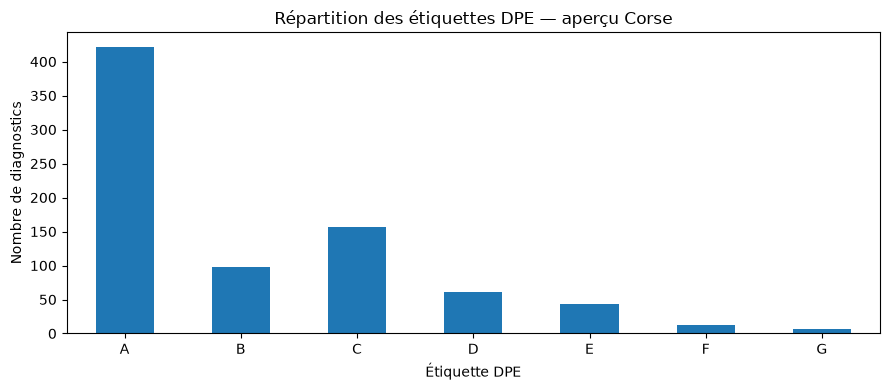

In [10]:
if "df_corse" in globals() and "etiquette_dpe" in df_corse.columns:
    classes = list("ABCDEFG")
    effectifs = df_corse["etiquette_dpe"].value_counts().reindex(classes, fill_value=0)

    ax = effectifs.plot(kind="bar", figsize=(9, 4))
    ax.set_title("Répartition des étiquettes DPE — aperçu Corse")
    ax.set_xlabel("Étiquette DPE")
    ax.set_ylabel("Nombre de diagnostics")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("Graphique indisponible : vérifier la fusion et la colonne etiquette_dpe.")